In [10]:
!pip install numpy matplotlib scikit-learn pillow kagglehub

In [11]:
import os
import re
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

import kagglehub

path = kagglehub.dataset_download(
    "tavarez/the-orl-database-for-training-and-testing"
)

print("Dataset location:", path)
print("Dataset downloaded successfully.")

Using Colab cache for faster access to the 'the-orl-database-for-training-and-testing' dataset.
Dataset location: /kaggle/input/the-orl-database-for-training-and-testing
Dataset downloaded successfully.


In [12]:
root = Path(path)

all_files = [
    file for file in root.rglob("*")
    if file.is_file()
]

image_extensions = {".pgm", ".png", ".jpg", ".jpeg", ".bmp"}

image_files = [
    file for file in all_files
    if file.suffix.lower() in image_extensions
]

print("Total files:", len(all_files))
print("Image files found:", len(image_files))
print("\nSample image paths:")

for file in image_files[:15]:
    print(file.relative_to(root))

Total files: 410
Image files found: 410

Sample image paths:
313_32.jpg
343_35.jpg
148_15.jpg
273_28.jpg
193_20.jpg
311_32.jpg
391_40.jpg
238_24.jpg
194_20.jpg
243_25.jpg
276_28.jpg
24_3.jpg
60_6.jpg
261_27.jpg
155_16.jpg


In [14]:

X, y = [], []
image_size = (92, 112)

for file in image_files:
    match = re.fullmatch(r"(\d+)_(\d+)", file.stem)

    if not match:
        continue

    image_number = int(match.group(1))
    label = int(match.group(2))

    # Keep only the 40 standard ORL identities
    if label < 1 or label > 40:
        continue

    try:
        with Image.open(file) as img:
            img = img.convert("L").resize(image_size)
            image_array = np.asarray(img, dtype=np.float32) / 255.0

            X.append(image_array.flatten())
            y.append(label)

    except Exception as error:
        print("Skipping:", file.name, error)

X = np.array(X, dtype=np.float32)
y = np.array(y)

print("Feature matrix:", X.shape)
print("Total images:", len(X))
print("Unique identities:", len(np.unique(y)))
print("Images per identity:", dict(zip(*np.unique(y, return_counts=True))))

assert len(X) == 400, "Expected 400 images. Check the dataset."
assert len(np.unique(y)) == 40, "Expected 40 identities."
assert np.all(np.unique(y, return_counts=True)[1] == 10), \
    "Expected 10 images per identity."


Feature matrix: (400, 10304)
Total images: 400
Unique identities: 40
Images per identity: {np.int64(1): np.int64(10), np.int64(2): np.int64(10), np.int64(3): np.int64(10), np.int64(4): np.int64(10), np.int64(5): np.int64(10), np.int64(6): np.int64(10), np.int64(7): np.int64(10), np.int64(8): np.int64(10), np.int64(9): np.int64(10), np.int64(10): np.int64(10), np.int64(11): np.int64(10), np.int64(12): np.int64(10), np.int64(13): np.int64(10), np.int64(14): np.int64(10), np.int64(15): np.int64(10), np.int64(16): np.int64(10), np.int64(17): np.int64(10), np.int64(18): np.int64(10), np.int64(19): np.int64(10), np.int64(20): np.int64(10), np.int64(21): np.int64(10), np.int64(22): np.int64(10), np.int64(23): np.int64(10), np.int64(24): np.int64(10), np.int64(25): np.int64(10), np.int64(26): np.int64(10), np.int64(27): np.int64(10), np.int64(28): np.int64(10), np.int64(29): np.int64(10), np.int64(30): np.int64(10), np.int64(31): np.int64(10), np.int64(32): np.int64(10), np.int64(33): np.int64

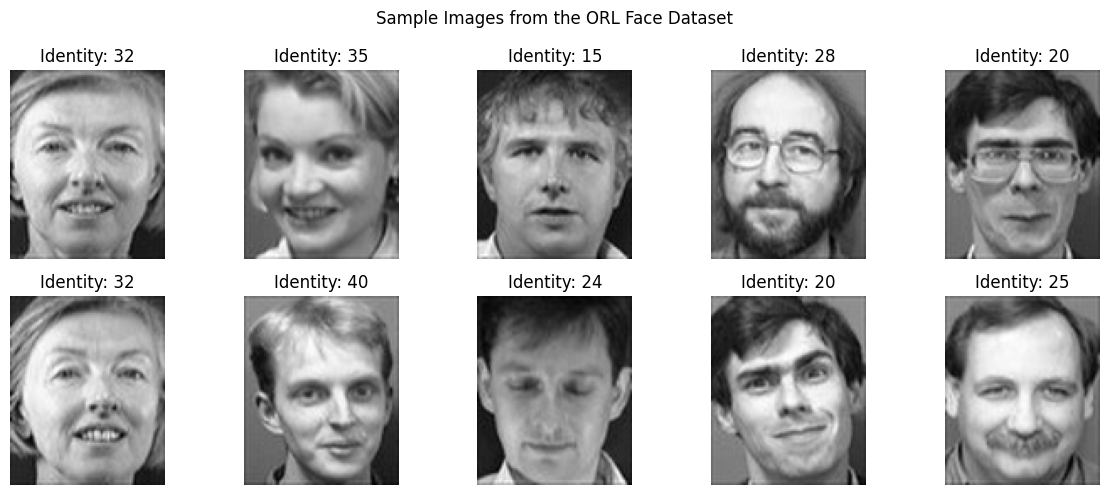

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X[i].reshape(image_size[1], image_size[0]), cmap="gray")
    ax.set_title(f"Identity: {y[i]}")
    ax.axis("off")

plt.suptitle("Sample Images from the ORL Face Dataset")
plt.tight_layout()
plt.show()

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape[0])
print("Testing images:", X_test.shape[0])
print("Number of features per image:", X_train.shape[1])
print("Training identities:", len(np.unique(y_train)))
print("Testing identities:", len(np.unique(y_test)))

Training images: 280
Testing images: 120
Number of features per image: 10304
Training identities: 40
Testing identities: 40


In [17]:
pca = PCA(n_components=100, svd_solver="randomized", random_state=42)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Original training shape:", X_train.shape)
print("Training shape after PCA:", X_train_pca.shape)
print("Testing shape after PCA:", X_test_pca.shape)

total_variance = np.sum(pca.explained_variance_ratio_)
print(f"Variance retained by 100 components: {total_variance:.4f}")
print(f"Percentage of variance retained: {total_variance * 100:.2f}%")

Original training shape: (280, 10304)
Training shape after PCA: (280, 100)
Testing shape after PCA: (120, 100)
Variance retained by 100 components: 0.9325
Percentage of variance retained: 93.25%


In [25]:

# Apply Singular Value Decomposition (SVD)

# Center the data using the training-set mean
mean_face = np.mean(X_train, axis=0)

X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

# Perform SVD
U, singular_values, VT = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

# Use 50 components for SVD
n_svd_components = 50
svd_components = VT[:n_svd_components].T

# Project training and testing images into the SVD space
X_train_svd = X_train_centered @ svd_components
X_test_svd = X_test_centered @ svd_components

print("Original training shape:", X_train.shape)
print("Training shape after SVD:", X_train_svd.shape)
print("Testing shape after SVD:", X_test_svd.shape)
print("Number of SVD components:", n_svd_components)


Original training shape: (280, 10304)
Training shape after SVD: (280, 50)
Testing shape after SVD: (120, 50)
Number of SVD components: 50


In [26]:
n_classes = len(np.unique(y_train))
n_lda_components = min(n_classes - 1, X_train.shape[0] - n_classes)

lda = LinearDiscriminantAnalysis(n_components=n_lda_components)

X_train_lda = lda.fit_transform(X_train, y_train)
X_test_lda = lda.transform(X_test)

print("Number of LDA components:", n_lda_components)
print("Training shape after LDA:", X_train_lda.shape)
print("Testing shape after LDA:", X_test_lda.shape)

Number of LDA components: 39
Training shape after LDA: (280, 39)
Testing shape after LDA: (120, 39)


In [27]:
representations = {
    "PCA": (X_train_pca, X_test_pca),
    "SVD": (X_train_svd, X_test_svd),
    "LDA": (X_train_lda, X_test_lda)
}

results = {}

for method, (train_features, test_features) in representations.items():
    classifier = KNeighborsClassifier(n_neighbors=1)

    classifier.fit(train_features, y_train)
    predictions = classifier.predict(test_features)

    accuracy = accuracy_score(y_test, predictions)
    results[method] = accuracy

    print(f"\n{method} Results")
    print("-" * 30)
    print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nFinal Accuracy Comparison")
for method, accuracy in results.items():
    print(f"{method}: {accuracy * 100:.2f}%")


PCA Results
------------------------------
Accuracy: 96.67%

SVD Results
------------------------------
Accuracy: 97.50%

LDA Results
------------------------------
Accuracy: 97.50%

Final Accuracy Comparison
PCA: 96.67%
SVD: 97.50%
LDA: 97.50%


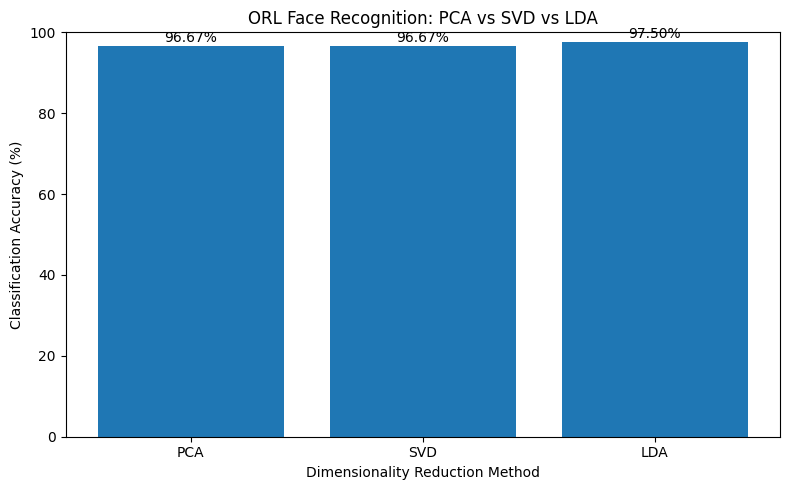

In [21]:
methods = list(results.keys())
accuracies = [results[method] * 100 for method in methods]

plt.figure(figsize=(8, 5))
bars = plt.bar(methods, accuracies)

plt.title("ORL Face Recognition: PCA vs SVD vs LDA")
plt.xlabel("Dimensionality Reduction Method")
plt.ylabel("Classification Accuracy (%)")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

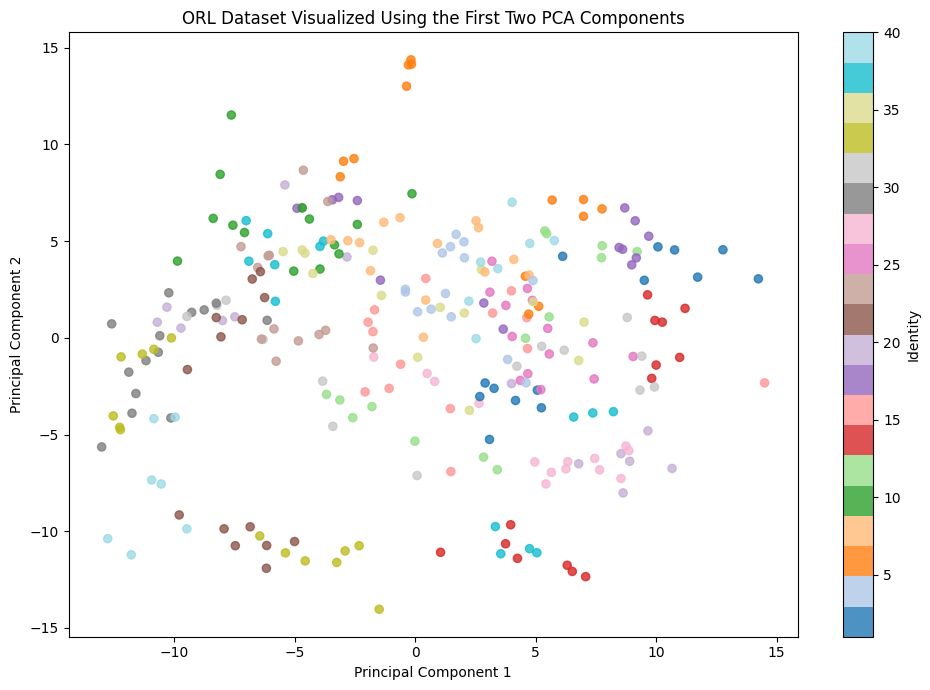

In [22]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="tab20",
    s=35,
    alpha=0.8
)

plt.title("ORL Dataset Visualized Using the First Two PCA Components")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Identity")
plt.tight_layout()
plt.show()

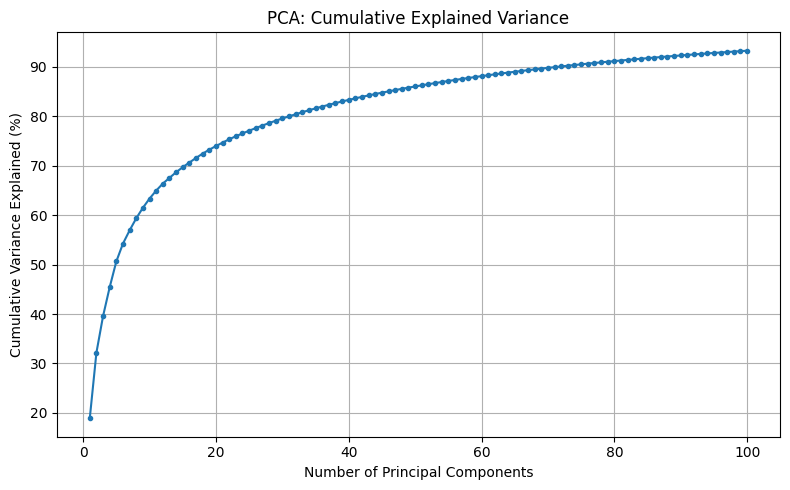

In [23]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="."
)

plt.title("PCA: Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Variance Explained (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

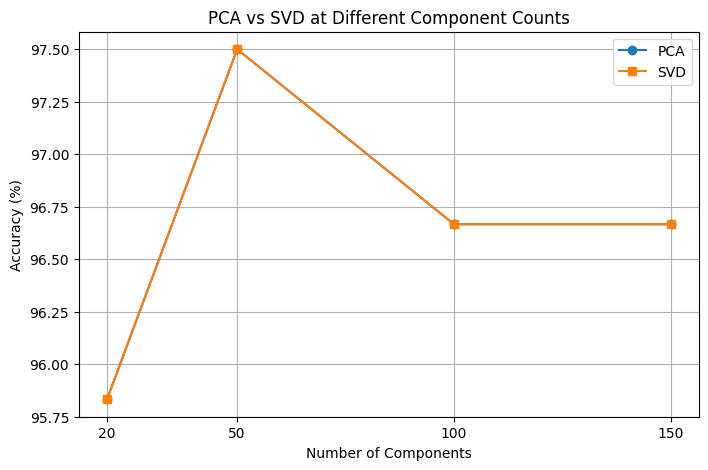

Components | PCA Accuracy | SVD Accuracy
        20 |       95.83% |       95.83%
        50 |       97.50% |       97.50%
       100 |       96.67% |       96.67%
       150 |       96.67% |       96.67%


In [24]:

from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

component_counts = [20, 50, 100, 150]
pca_accuracies = []
svd_accuracies = []

mean_face = X_train.mean(axis=0)
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

# Compute SVD once and reuse its components
U, singular_values, VT = np.linalg.svd(
    X_train_centered, full_matrices=False
)

for n in component_counts:
    # PCA
    pca_model = PCA(
        n_components=n, svd_solver="randomized", random_state=42
    )
    train_pca = pca_model.fit_transform(X_train)
    test_pca = pca_model.transform(X_test)

    clf_pca = KNeighborsClassifier(n_neighbors=1)
    clf_pca.fit(train_pca, y_train)
    pca_accuracies.append(
        accuracy_score(y_test, clf_pca.predict(test_pca)) * 100
    )

    # SVD
    components = VT[:n].T
    train_svd = X_train_centered @ components
    test_svd = X_test_centered @ components

    clf_svd = KNeighborsClassifier(n_neighbors=1)
    clf_svd.fit(train_svd, y_train)
    svd_accuracies.append(
        accuracy_score(y_test, clf_svd.predict(test_svd)) * 100
    )

plt.figure(figsize=(8, 5))
plt.plot(component_counts, pca_accuracies, marker="o", label="PCA")
plt.plot(component_counts, svd_accuracies, marker="s", label="SVD")
plt.xlabel("Number of Components")
plt.ylabel("Accuracy (%)")
plt.title("PCA vs SVD at Different Component Counts")
plt.xticks(component_counts)
plt.grid(True)
plt.legend()
plt.show()

print("Components | PCA Accuracy | SVD Accuracy")
for n, p, s in zip(component_counts, pca_accuracies, svd_accuracies):
    print(f"{n:10d} | {p:11.2f}% | {s:11.2f}%")
